# OWL reproduction and extension: run everything on one GPU PC

This notebook runs every experiment from the proposal (`proposal/ProjectProposal_TKP-XGHN.pdf`) on a local GPU through Anaconda. After each group of runs it shows the results next to the paper's numbers.

| Section | Proposal | Job file | Jobs |
|---|---|---|---|
| 1 | Sanity check: dense LLaMA-7B WikiText-2 perplexity is about 5.68 | (in this notebook) | 1 |
| 2 | R1 (Table 3) and R3 with lm-eval 0.4 (Table 4) | `experiments/r1.txt` | 18 |
| 3 | R2 (Table 8 / Figure 2) | `experiments/r2.txt` | 30 |
| 4 | R4 (Table 1 / Figure 1) | `experiments/r4.txt` | 14 |
| 5 | E2: dense LOD of all ten models | `experiments/e2.txt` | 10 |
| 6 | E1: OWL vs uniform on Qwen2.5 / Llama-3.x, shuffle control, seeds | `experiments/e1.txt` | 120 |
| 7 | E2 analysis: does the LOD predict the OWL gain? | (uses 2, 5, 6) | 0 |
| 8 | E3: M and lambda grid, then transfer to each family | `experiments/e3.txt` + 7 | 40 + up to 7 |
| 9 | R3 with the authors' lm-eval 0.3.0 scripts (optional, about 80 GB of checkpoints) | (in this notebook) | 6 |
| 10 | Collect everything into `results/summary.csv` | | |

E4 was dropped from the proposal, so this notebook does not run it.

**Short on time or GPU?** Section 1b runs `experiments/talk.txt`, the 84 perplexity-only jobs that fill the presentation (about 7 hours on an A100 or 16 on an L4, estimated). They write the same files as the full groups, so the later sections pick the results up and nothing is run twice.

**Two people.** Jobs are independent. Run this notebook on two machines with different `models=[...]` and commit both sets of `results/*/*.json`.

**How it works.** Each job is one `python -m owlrepro.run ...` line from a job file. The notebook starts it in a fresh process, so GPU memory is freed after every job. Output goes to `logs/<group>_<name>.log` and the result to `results/<group>/<name>.json`. A job whose JSON already exists is skipped. If anything stops (a crash, a reboot, Kernel > Interrupt), run the same cell again and it picks up where it left off. The analysis cells read whatever results exist, so you can run them before a group is finished.

## One-time setup (Anaconda Prompt)

```
cd path\to\NLP_CLASS
conda create -n owl python=3.11 -y
conda activate owl
nvidia-smi                       # top right shows the newest CUDA version your driver supports
# pick the matching command at https://pytorch.org/get-started/locally/ , for example:
pip install torch --index-url https://download.pytorch.org/whl/cu124
pip install -r requirements.txt
pip install jupyterlab ipykernel pandas matplotlib
python -m ipykernel install --user --name owl --display-name "Python (owl)"
jupyter lab
```

Open `notebooks/run_all.ipynb` and choose the kernel **Python (owl)**.

## Colab instead of a local PC

Open this notebook from GitHub in Colab (File > Open notebook > GitHub, `khangpt2k6/NLP_CLASS`), pick an L4 runtime (A100 only for LLaMA-13B) and run the cells in order. The setup cell clones the repo, installs the requirements, keeps the model cache on the VM disk and copies every finished result to `MyDrive/owl_results`, because Colab deletes the VM disk when the session ends. A new session copies them back and continues. Keep the tab open while jobs run. This path has not been tested on Colab yet.

**Disk.** All ten models together are about 105 GB in the Hugging Face cache, plus a few GB of datasets. Set `HF_HOME` in the next cell to a drive with room.

**Llama-3.x models** are gated. Request access on each model page (`meta-llama/Llama-3.2-1B`, `Llama-3.2-3B`, `Llama-3.1-8B`) with the same Hugging Face account you log in with below.

## 0. Setup

In [1]:
import glob
import json
import math
import os
import shlex
import shutil
import subprocess
import sys
import time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not (Path.cwd() / "owlrepro").is_dir() and not (Path.cwd().parent / "owlrepro").is_dir():
    # opened straight from GitHub: get the repo and its requirements first
    if not Path("/content/NLP_CLASS").is_dir():
        subprocess.run(["git", "clone", "https://github.com/khangpt2k6/NLP_CLASS.git", "/content/NLP_CLASS"],
                       check=True)
    os.chdir("/content/NLP_CLASS")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)

# repo root = the folder that contains owlrepro/ (this notebook lives in notebooks/)
ROOT = Path.cwd()
if not (ROOT / "owlrepro").is_dir() and (ROOT.parent / "owlrepro").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "owlrepro").is_dir(), f"can't find the repo from {Path.cwd()}"
os.chdir(ROOT)

# Where model weights and datasets are cached (about 105 GB for all models).
# To use another drive, change this, e.g. HF_HOME = r"D:\hf_cache"
# On Colab the cache stays on the VM disk, Google Drive is too small for the weights.
HF_HOME = os.environ.get("HF_HOME", "/content/hf_cache" if IN_COLAB else str(ROOT / ".hf_cache"))
os.environ["HF_HOME"] = HF_HOME
os.environ.setdefault("HF_HUB_DISABLE_SYMLINKS_WARNING", "1")  # Windows without developer mode
os.environ.setdefault("PYTHONUTF8", "1")                        # tqdm/datasets output on Windows consoles
os.environ.setdefault("TOKENIZERS_PARALLELISM", "false")

# Set True to also run models that are too big for the GPU. They are then partly offloaded to CPU RAM
# by accelerate (device_map="auto"). That is very slow and has not been tested with this code.
ALLOW_OFFLOAD = False

# Colab deletes the VM disk when the session ends. With BACKUP_DIR set, every finished result JSON is
# copied there, and copied back at startup, so a new session continues where the last one stopped.
BACKUP_DIR = None
if IN_COLAB:
    from google.colab import drive
    try:
        drive.mount("/content/drive")
        BACKUP_DIR = "/content/drive/MyDrive/owl_results"
    except Exception as e:  # no Drive: results stay on the VM, download them before the session ends
        print("Google Drive not mounted:", e)
if BACKUP_DIR:
    Path(BACKUP_DIR).mkdir(parents=True, exist_ok=True)
    shutil.copytree(BACKUP_DIR, ROOT / "results", dirs_exist_ok=True)

sys.path.insert(0, str(ROOT / "scripts"))
import make_jobs  # MODELS, NEW_MODELS, job()
import estimate   # rough run times, is_done()

print("repo   ", ROOT)
print("python ", sys.executable)
print("HF_HOME", HF_HOME)
print("backup ", BACKUP_DIR)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
repo    /content/NLP_CLASS
python  /usr/bin/python3
HF_HOME /content/hf_cache
backup  /content/drive/MyDrive/owl_results


In [2]:
import torch
import transformers
import datasets

print("torch", torch.__version__, "| CUDA build", torch.version.cuda, "| transformers", transformers.__version__,
      "| datasets", datasets.__version__)
try:
    import lm_eval
    print("lm_eval", lm_eval.__version__)
except Exception as e:
    print("lm_eval NOT importable:", e)

if torch.cuda.is_available():
    props = torch.cuda.get_device_properties(0)
    VRAM_GB = props.total_memory / 2**30
    print(f"GPU {props.name}, {VRAM_GB:.1f} GB, bf16 {'yes' if torch.cuda.is_bf16_supported() else 'no'}")
else:
    VRAM_GB = 0.0
    print("WARNING: torch sees no GPU. Reinstall torch with the CUDA build for your driver (see setup above).")

Path(HF_HOME).mkdir(parents=True, exist_ok=True)
print(f"free disk at HF_HOME: {shutil.disk_usage(HF_HOME).free / 2**30:.0f} GB")

torch 2.14.1+cu130 | CUDA build 13.0 | transformers 5.22.1 | datasets 4.8.5
lm_eval 0.4.13
GPU NVIDIA A100-SXM4-40GB, 39.5 GB, bf16 yes
free disk at HF_HOME: 196 GB


Log in to Hugging Face (needed only for the gated Llama-3.x models). If it says you are already logged in, skip the login prompt.

In [3]:
from huggingface_hub import whoami, login

if IN_COLAB and not os.environ.get("HF_TOKEN"):
    # a Colab secret named HF_TOKEN (key icon on the left, notebook access on) is passed on to the jobs
    try:
        from google.colab import userdata
        os.environ["HF_TOKEN"] = userdata.get("HF_TOKEN")
    except Exception as e:
        print("no Colab secret HF_TOKEN:", type(e).__name__)

try:
    print("logged in as", whoami()["name"])
except Exception:
    login()  # paste a token from https://huggingface.co/settings/tokens (read access is enough)

logged in as xuangiahannguyen


### Job runner

`run_group("r1")` runs every job of `experiments/r1.txt` that has no result yet. Options:
- `models=["llama7b"]`: only these models (short names from `scripts/make_jobs.py`)
- `max_jobs=3`: stop after 3 jobs
- `dry_run=True`: only print what would run, with the estimated minutes of each job

Jobs whose estimated peak memory is above the GPU's are skipped unless `ALLOW_OFFLOAD = True`. The estimate is rough: about 18 GB for a 7B model and 31 GB for LLaMA-13B, as in the proposal.

The time estimates come from `scripts/estimate.py`. They are rough (up to 2x off) until three jobs have finished on this GPU, then they are rescaled from the measured times. A job counts as done when its JSON exists, and also holds zero-shot results if the job asks for them.

In [4]:
SHORT = {hf: short for short, (hf, _, _) in make_jobs.MODELS.items()}
PARAMS_B = {  # parameter counts in billions, for the memory estimate
    "huggyllama/llama-7b": 6.7, "huggyllama/llama-13b": 13.0, "facebook/opt-6.7b": 6.7,
    "Qwen/Qwen2.5-0.5B": 0.5, "Qwen/Qwen2.5-1.5B": 1.5, "Qwen/Qwen2.5-3B": 3.1, "Qwen/Qwen2.5-7B": 7.6,
    "meta-llama/Llama-3.2-1B": 1.2, "meta-llama/Llama-3.2-3B": 3.2, "meta-llama/Llama-3.1-8B": 8.0,
    "HuggingFaceTB/SmolLM2-135M": 0.135,
}


GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else ""


def est_gb(hf_name):
    # fp16/bf16 weights + one block's calibration activations + CUDA overhead (18 GB at 7B, 33 GB at 13B)
    return 2.35 * PARAMS_B.get(hf_name, 7.0) + 2.0


def job_args(line):
    args = shlex.split(line)
    return args, dict(zip(args[::2], args[1::2]))


def run_job(line, quiet_progress=True):
    """Run one owlrepro.run job in a fresh process. Returns True if the result JSON was written."""
    args, a = job_args(line)
    out = Path(a["--out"])
    log = ROOT / "logs" / f"{out.parent.name}_{out.stem}.log"
    log.parent.mkdir(exist_ok=True)
    cmd = [sys.executable, "-u", "-m", "owlrepro.run", *args]
    t0 = time.time()
    with open(log, "w", encoding="utf-8") as f:
        f.write(" ".join(cmd) + "\n")
        p = subprocess.Popen(cmd, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                             text=True, encoding="utf-8", errors="replace", bufsize=1)
        try:
            for ln in p.stdout:
                f.write(ln)
                f.flush()
                if quiet_progress and ("%|" in ln or "it/s]" in ln or "s/it]" in ln):
                    continue  # progress bars go to the log only
                print("   ", ln, end="")
        except KeyboardInterrupt:
            p.kill()
            p.wait()
            print(f"\ninterrupted, killed the job. Partial log: {log}")
            raise
        p.wait()
    mins = (time.time() - t0) / 60
    if p.returncode == 0 and out.exists():
        print(f"  done in {mins:.1f} min -> {out}")
        if BACKUP_DIR:
            dst = Path(BACKUP_DIR) / out.parent.name / out.name
            dst.parent.mkdir(parents=True, exist_ok=True)
            shutil.copy2(out, dst)
        return True
    print(f"  FAILED (exit {p.returncode}) after {mins:.1f} min, full output in {log}")
    return False


def eta(lines):
    """Rough time for these job lines on this GPU: (estimate dict, text)."""
    e = estimate.estimate(lines, GPU_NAME or "A100", str(ROOT))
    note = (f"rescaled from {e['calibrated_on']} finished jobs" if e["calibrated_on"] >= 3
            else "not calibrated yet, can be 2x off")
    return e, f"about {e['minutes'] / 60:.1f} h on {GPU_NAME or 'an A100 (no GPU here)'} ({note})"


def run_lines(lines, models=None, max_jobs=None, dry_run=False, label=""):
    todo, done, too_big = [], 0, []
    for line in lines:
        _, a = job_args(line)
        short = SHORT.get(a["--model"], a["--model"])
        if models and short not in models:
            continue
        if estimate.is_done(a, str(ROOT)):
            done += 1
        elif est_gb(a["--model"]) > VRAM_GB and not ALLOW_OFFLOAD:
            too_big.append(line)
        else:
            todo.append(line)
    if max_jobs is not None:
        todo = todo[:max_jobs]
    print(f"{label}: {done} done, {len(todo)} to run, {len(too_big)} skipped (need more than {VRAM_GB:.0f} GB)")
    for line in too_big:
        _, a = job_args(line)
        print(f"  too big (~{est_gb(a['--model']):.0f} GB): {a['--out']}")
    e, text = eta(todo)
    if todo:
        print(f"  estimated time: {text}, plus about {e['download_minutes']:.0f} min of downloads "
              "for models that are not cached yet")
    if dry_run:
        for line, m in zip(todo, e["per_job"]):
            print(f"  would run ({m:3.0f} min):", job_args(line)[1]["--out"])
        return
    failed = []
    for k, line in enumerate(todo, 1):
        _, a = job_args(line)
        print(f"[{k}/{len(todo)}] {time.strftime('%H:%M')} {a['--out']} (about {e['per_job'][k - 1]:.0f} min)")
        if not run_job(line):
            failed.append(a["--out"])
    print(f"{label}: finished, {len(todo) - len(failed)} ok, {len(failed)} failed")
    for f in failed:
        print("  failed:", f)


def group_lines(group):
    return [l.strip() for l in open(ROOT / "experiments" / f"{group}.txt", encoding="utf-8") if l.strip()]


def run_group(group, **kw):
    run_lines(group_lines(group), label=group, **kw)


def status():
    # talk is a subset of the other groups, so do not add its hours to theirs
    for g in ["talk", "r1", "r2", "r4", "e1", "e2", "e3"]:
        lines = group_lines(g)
        todo = [l for l in lines if not estimate.is_done(job_args(l)[1], str(ROOT))]
        left = f", {eta(todo)[1]} left" if todo else ""
        print(f"{g}: {len(lines) - len(todo)}/{len(lines)} done{left}")

Regenerate the job files from `scripts/make_jobs.py` (no change if the script is unchanged), then show progress.

In [5]:
subprocess.run([sys.executable, "scripts/make_jobs.py"], cwd=ROOT, check=True)
status()

talk: 84/84 done
r1: 18/18 done
r2: 30/30 done
r4: 14/14 done
e1: 34/120 done, about 4.2 h on NVIDIA A100-SXM4-40GB (rescaled from 100 finished jobs) left
e2: 10/10 done
e3: 0/40 done, about 0.6 h on NVIDIA A100-SXM4-40GB (rescaled from 100 finished jobs) left


Unit tests (CPU, tiny random models, no downloads) and a short smoke run on SmolLM2-135M.

In [6]:
subprocess.run([sys.executable, "-m", "pytest", "tests", "-q"], cwd=ROOT)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', 'tests', '-q'], returncode=0)

In [7]:
run_job("--model HuggingFaceTB/SmolLM2-135M --method wanda --alloc owl --sparsity 0.5 --nsamples 4 --seqlen 256 "
        "--eval wikitext2,c4 --max_eval_windows 16 --lod 5 --out results/smoke/test.json")

    skip, results/smoke/test.json exists
  done in 0.1 min -> results/smoke/test.json


True

### Analysis helpers

These read every `results/<group>/*.json` into a table. Perplexities are on WikiText-2 (`wiki`) and the C4 validation shard (`c4`). `zs` is the mean zero-shot `acc` over the seven tasks.

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
FAMILY = {"llama7b": "llama1", "llama13b": "llama1", "opt6.7b": "opt",
          "qwen2.5-0.5b": "qwen2.5", "qwen2.5-1.5b": "qwen2.5", "qwen2.5-3b": "qwen2.5", "qwen2.5-7b": "qwen2.5",
          "llama3.2-1b": "llama3", "llama3.2-3b": "llama3", "llama3.1-8b": "llama3"}


def load(*groups):
    rows = []
    for g in groups:
        for p in sorted(glob.glob(str(ROOT / "results" / g / "*.json"))):
            r = json.load(open(p, encoding="utf-8"))
            a = r["args"]
            dense = a["method"] == "dense"
            short = SHORT.get(a["model"], a["model"])
            rows.append(dict(
                group=g, model=short, family=FAMILY.get(short, "?"), params=PARAMS_B.get(a["model"]),
                method=a["method"], alloc="dense" if dense else a["alloc"], s=0.0 if dense else a["sparsity"],
                M=a["M"], lam=a["lam"], seed=a.get("seed", 0),
                perm=a.get("shuffle_seed", 0) if a["alloc"] == "owl_shuffle" else 0, calib=a["calib"],
                wiki=r["ppl"].get("wikitext2"), c4=r["ppl"].get("c4"),
                zs=(r.get("zeroshot") or {}).get("mean_acc"), sparsity=r["sparsity"],
                minutes=r["total_seconds"] / 60, raw=r))
    cols = ["group", "model", "family", "params", "method", "alloc", "s", "M", "lam", "seed", "perm", "calib",
            "wiki", "c4", "zs", "sparsity", "minutes", "raw"]
    return pd.DataFrame(rows, columns=cols)


def lod_of(raw, M, key="lod_dense"):
    d = raw.get(key) or {}
    return d.get(str(float(M)))


def show(df, cols=None):
    display(df[cols] if cols else df.drop(columns=["raw"], errors="ignore"))

## 1. Sanity check: dense LLaMA-7B

The proposal starts with this check. The paper reports a dense WikiText-2 perplexity of **5.68**. If ours is more than about 1% off, stop and look for the cause (tokenizer, dtype, dataset version) before running anything else. The first run downloads LLaMA-7B (about 13 GB) and the C4 shard and WikiText-2.

In [9]:
SANITY = "results/sanity/llama7b_dense.json"
run_job(f"--model huggyllama/llama-7b --method dense --eval wikitext2 --out {SANITY}")
ppl = json.load(open(SANITY))["ppl"]["wikitext2"]
gap = (ppl - 5.68) / 5.68
print(f"dense LLaMA-7B WikiText-2 ppl {ppl:.3f} vs paper 5.68 ({gap:+.1%})")
assert abs(gap) < 0.01, "more than 1% from the paper: check the setup before running the rest"
print("PASS")

    skip, results/sanity/llama7b_dense.json exists
  done in 0.1 min -> results/sanity/llama7b_dense.json
dense LLaMA-7B WikiText-2 ppl 5.677 vs paper 5.68 (-0.1%)
PASS


## 1b. Presentation cut: `experiments/talk.txt` (optional)

84 perplexity-only jobs: all of R1, the dense LOD of the ten models (E2), E1 at 70% only, R4 on LLaMA-7B, and a thin R2 (uniform and OWL over the whole sweep, the other allocations at 70%). Zero-shot, the 50% and 60% runs, the controls and E3 are left to the sections below.

These are the same files the full groups write, so the analysis cells in sections 2 to 7 work on them, and a later `run_group("r1")` or `run_group("e1")` only runs what is missing. Jobs there that ask for zero-shot run again over a perplexity-only file.

Two people can split the work by model. `dry_run=True` lists the jobs with their estimated minutes.

In [10]:
# person A: LLaMA-7B and OPT-6.7B fit a 24 GB card, LLaMA-13B needs about 31 GB (A100 or a 48 GB card)
PAPER_MODELS = ["llama7b", "opt6.7b", "llama13b"]
run_group("talk", models=PAPER_MODELS, dry_run=True)

talk: 42 done, 0 to run, 0 skipped (need more than 39 GB)


In [11]:
run_group("talk", models=PAPER_MODELS)

talk: 42 done, 0 to run, 0 skipped (need more than 39 GB)
talk: finished, 0 ok, 0 failed


In [12]:
# person B: the seven Qwen2.5 and Llama-3.x models (the five up to 3B also fit a T4)
run_group("talk", models=make_jobs.NEW_MODELS)

talk: 42 done, 0 to run, 0 skipped (need more than 39 GB)
talk: finished, 0 ok, 0 failed


## 2. R1: Table 3 at 70% sparsity (and zero-shot of Table 4 on LLaMA-7B)

LLaMA-7B and OPT-6.7B need a 24 GB GPU. LLaMA-13B needs about 31 GB, so on a smaller card those jobs are listed as skipped. Run them on GAIVI or Colab A100 and copy their JSON files into `results/r1/`. The LLaMA-7B jobs also run the seven zero-shot tasks, which takes a while.

Start with LLaMA-7B only, then remove `models=` to run the rest.

In [13]:
run_group("r1", models=["llama7b"])

r1: 6 done, 0 to run, 0 skipped (need more than 39 GB)
r1: finished, 0 ok, 0 failed


In [14]:
run_group("r1")

r1: 18 done, 0 to run, 0 skipped (need more than 39 GB)
r1: finished, 0 ok, 0 failed


In [15]:
PAPER_T3 = {  # WikiText ppl at 70%, Table 3
    "llama7b":  {"dense": 5.68,  "magnitude/uniform": 48419.12,  "wanda/uniform": 85.77,  "wanda/owl": 24.55,
                 "sparsegpt/uniform": 26.30, "sparsegpt/owl": 19.49},
    "llama13b": {"dense": 5.09,  "magnitude/uniform": 84539.45,  "wanda/uniform": 55.90,  "wanda/owl": 17.17,
                 "sparsegpt/uniform": 19.24, "sparsegpt/owl": 14.55},
    "opt6.7b":  {"dense": 10.13, "magnitude/uniform": 290985.03, "wanda/uniform": 162.92, "wanda/owl": 40.22,
                 "sparsegpt/uniform": 20.29, "sparsegpt/owl": 22.48},
}


def key(r):
    return "dense" if r.method == "dense" else f"{r.method}/{r.alloc}"


r1 = load("r1")
if len(r1):
    r1["setting"] = r1.apply(key, axis=1)
    r1["paper"] = pd.to_numeric(pd.Series([PAPER_T3.get(m, {}).get(k) for m, k in zip(r1.model, r1.setting)],
                                          index=r1.index), errors="coerce")
    r1["diff"] = r1.wiki / r1.paper - 1
    r1["within_15%"] = r1["diff"].abs() <= 0.15
    show(r1, ["model", "setting", "wiki", "paper", "diff", "within_15%", "sparsity", "minutes"])

    # direction of the OWL effect per model and method; within 2% counts as a tie
    def direction(uni, owl):
        rel = (owl - uni) / uni
        return "tie" if abs(rel) < 0.02 else ("OWL better" if rel < 0 else "OWL worse")

    rows = []
    for m in PAPER_T3:
        for meth in ["wanda", "sparsegpt"]:
            got = r1[(r1.model == m) & (r1.method == meth)].set_index("alloc").wiki
            if {"uniform", "owl"} <= set(got.index):
                p = PAPER_T3[m]
                rows.append(dict(model=m, method=meth, ours=direction(got["uniform"], got["owl"]),
                                 paper=direction(p[f"{meth}/uniform"], p[f"{meth}/owl"]),
                                 ours_gain=got["uniform"] - got["owl"],
                                 paper_gain=p[f"{meth}/uniform"] - p[f"{meth}/owl"]))
    if rows:
        d = pd.DataFrame(rows)
        d["match"] = d.ours == d.paper
        display(d)

    # C1 is only judged once every pruned setting of all three models has a result
    need = {(m, k) for m in PAPER_T3 for k in PAPER_T3[m] if k != "dense"}
    missing = sorted(need - set(zip(r1.model, r1.setting)))
    pruned = r1[r1.method != "dense"]
    if missing:
        print(f"C1 not judged yet, {len(missing)} of {len(need)} pruned settings missing:",
              ", ".join(f"{m} {k}" for m, k in missing))
    else:
        print("C1 reproduced (all directions match and all 70% ppl within 15%):",
              bool(d.match.all() and pruned["within_15%"].all()))
        # magnitude ppl at 70% is in the tens of thousands and swings with small numeric changes,
        # so also show the result with the 15% band on Wanda and SparseGPT only
        ws = pruned[pruned.method != "magnitude"]
        print("  same, 15% band on Wanda/SparseGPT only:", bool(d.match.all() and ws["within_15%"].all()))

,model,setting,wiki,paper,diff,within_15%,sparsity,minutes
0,llama13b,dense,5.090580,5.09,0.000114,True,0.000001,2.341672
1,llama13b,magnitude/uniform,84522.921875,84539.45,-0.000196,True,0.700161,3.266677
2,llama13b,sparsegpt/owl,14.634319,14.55,0.005795,True,0.700001,15.984234
3,llama13b,sparsegpt/uniform,19.322525,19.24,0.004289,True,0.700001,14.958907
4,llama13b,wanda/owl,16.921316,17.17,-0.014484,True,0.699916,3.079509
5,llama13b,wanda/uniform,56.315006,55.90,0.007424,True,0.699987,2.470999
6,llama7b,dense,5.677084,5.68,-0.000513,True,0.000001,10.806215
7,llama7b,magnitude/uniform,48835.796875,48419.12,0.008606,True,0.700172,10.761694
8,llama7b,sparsegpt/owl,18.889128,19.49,-0.030830,True,0.700001,18.047608
9,llama7b,sparsegpt/uniform,26.396591,26.30,0.003673,True,0.700001,17.578245


,model,method,ours,paper,ours_gain,paper_gain,match
0,llama7b,wanda,OWL better,OWL better,60.522142,61.22,True
1,llama7b,sparsegpt,OWL better,OWL better,7.507463,6.81,True
2,llama13b,wanda,OWL better,OWL better,39.393690,38.73,True
3,llama13b,sparsegpt,OWL better,OWL better,4.688206,4.69,True
4,opt6.7b,wanda,OWL better,OWL better,119.203720,122.70,True
5,opt6.7b,sparsegpt,OWL worse,OWL worse,-1.192434,-2.19,True


C1 reproduced (all directions match and all 70% ppl within 15%): False
  same, 15% band on Wanda/SparseGPT only: True


### R3 (lm-eval 0.4): zero-shot on LLaMA-7B at 70%

These come from our `--zeroshot all` runs in R1 (lm-eval 0.4). Prompts and metrics differ from the authors' lm-eval 0.3.0 pipeline, so compare the ranking and the OWL gain, not exact numbers. Section 9 runs the authors' scripts. Table 4 does not say whether it uses `acc` or `acc_norm`, so both are shown.

In [16]:
TASKS = ["boolq", "rte", "hellaswag", "winogrande", "arc_easy", "arc_challenge", "openbookqa"]
PAPER_T4 = {  # LLaMA-7B, 70%, Table 4 (%)
    "dense":             [75.14, 66.43, 74.80, 70.01, 67.67, 41.38, 41.40, 62.40],
    "magnitude/uniform": [38.29, 52.71, 24.68, 51.46, 26.98, 22.35, 25.80, 34.61],
    "wanda/uniform":     [55.11, 57.40, 31.83, 51.38, 34.22, 19.80, 26.00, 39.39],
    "wanda/owl":         [62.48, 58.48, 44.79, 58.72, 45.03, 26.19, 29.60, 46.47],
    "sparsegpt/uniform": [64.53, 53.79, 42.11, 58.64, 43.06, 24.57, 27.80, 44.93],
    "sparsegpt/owl":     [67.13, 53.43, 48.56, 62.03, 45.41, 27.65, 32.00, 48.03],
}
zs_rows = []
for _, r in load("r1").query("model == 'llama7b'").iterrows():
    z = r.raw.get("zeroshot")
    if not z:
        continue
    k = key(r)
    for metric in ["acc", "acc_norm"]:
        vals = [100 * z[t][metric] if t in z and metric in z[t] else np.nan for t in TASKS]
        zs_rows.append(dict(setting=k, source=f"ours {metric}", **dict(zip(TASKS, vals)), mean=np.nanmean(vals)))
    zs_rows.append(dict(setting=k, source="paper", **dict(zip(TASKS + ["mean"], PAPER_T4.get(k, [np.nan] * 8)))))
if zs_rows:
    display(pd.DataFrame(zs_rows).set_index(["setting", "source"]).round(2))

boolq    rte  hellaswag  winogrande  arc_easy  arc_challenge  openbookqa   mean
setting           source                                                                                        
dense             ours acc       76.76  67.87      57.04       70.32     75.55          42.32        33.6  60.49
                  ours acc_norm    NaN    NaN      76.07         NaN     71.93          44.20        43.8  59.00
                  paper          75.14  66.43      74.80       70.01     67.67          41.38        41.4  62.40
magnitude/uniform ours acc       49.57  49.82      25.76       47.83     24.33          22.70        13.8  33.40
                  ours acc_norm    NaN    NaN      25.55         NaN     23.91          26.28        24.2  24.98
                  paper          38.29  52.71      24.68       51.46     26.98          22.35        25.8  34.61
sparsegpt/owl     ours acc       67.22  53.79      36.68       61.88     49.12          25.85        19.0  44.79
                  ours acc_norm    NaN    NaN      47.81         NaN     45.71          27.99        30.8  38.08
                  paper          67.13  53.43      48.56       62.03     45.41          27.65        32.0  48.03
sparsegpt/uniform ours acc       63.24  53.43      33.18       57.77     43.98          22.87        18.2  41.81
                  ours acc_norm    NaN    NaN      41.09         NaN     40.91          25.00        29.8  34.20
                  paper          64.53  53.79      42.11       58.64     43.06          24.57        27.8  44.93
wanda/owl         ours acc       62.29  53.79      34.57       58.96     46.42          24.49        18.0  42.65
                  ours acc_norm    NaN    NaN      43.70         NaN     44.15          26.88        31.0  36.43
                  paper          62.48  58.48      44.79       58.72     45.03          26.19        29.6  46.47
wanda/uniform     ours acc       57.06  55.60      28.34       49.25     30.35          18.43        13.0  36.00
                  ours acc_norm    NaN    NaN      30.53         NaN     30.60          22.35        26.4  27.47
                  paper          55.11  57.40      31.83       51.38     34.22          19.80        26.0  39.39

## 3. R2: Table 8 / Figure 2, 40% to 80% on LLaMA-7B with Wanda

30 jobs on LLaMA-7B (Wanda is fast, so most of the time is perplexity evaluation).

In [17]:
run_group("r2")

r2: 30 done, 0 to run, 0 skipped (need more than 39 GB)
r2: finished, 0 ok, 0 failed


ours                                            paper                                       
s             0.4      0.5      0.6        0.7       0.8       0.4       0.5       0.6      0.7       0.8
er           6.57     7.80    12.37     115.96   9064.97      6.55      7.74     12.16   112.03  11151.18
er_plus      6.57     7.85    12.98     165.01  11826.75      6.62      8.00     14.04   229.17   6013.91
global   13862.30  4701.28  6841.50  319659.50  46459.09  10762.00  14848.00  17765.00  5147.00  39918.56
owl          6.39     7.22     9.35      24.32   1578.56      6.39      7.22      9.35    24.54   1002.87
owl_inv      6.51     8.03    26.08     974.84  11176.36      6.51      8.03     26.05   822.23   9616.08
uniform      6.39     7.26    10.70      84.84   5716.10      6.38      7.26     10.70    85.77   3499.88

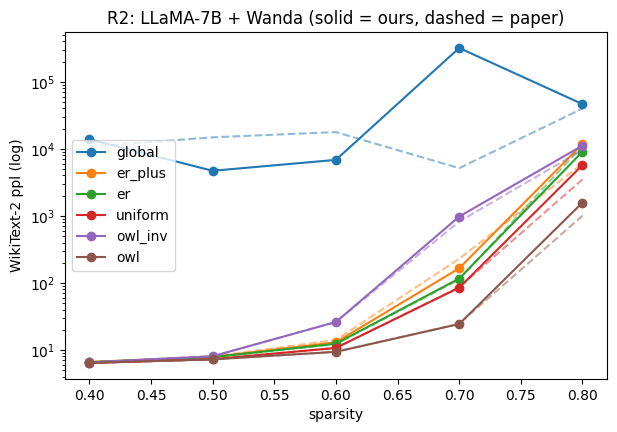

In [18]:
SP = [0.4, 0.5, 0.6, 0.7, 0.8]
PAPER_T8 = {  # Table 8, WikiText ppl of LLaMA-7B + Wanda
    "global":   [10762, 14848, 17765, 5147, 39918.56],
    "er_plus":  [6.62, 8.00, 14.04, 229.17, 6013.91],
    "er":       [6.55, 7.74, 12.16, 112.03, 11151.18],
    "uniform":  [6.38, 7.26, 10.70, 85.77, 3499.88],
    "owl_inv":  [6.51, 8.03, 26.05, 822.23, 9616.08],
    "owl":      [6.39, 7.22, 9.35, 24.54, 1002.87],
}
r2 = load("r2")
if len(r2):
    ours = r2.pivot_table(index="alloc", columns="s", values="wiki")
    paper = pd.DataFrame(PAPER_T8, index=SP).T
    display(pd.concat({"ours": ours, "paper": paper}, axis=1).round(2))

    fig, ax = plt.subplots(figsize=(7, 4.5))
    for i, alloc in enumerate(PAPER_T8):
        c = f"C{i}"
        ax.plot(SP, PAPER_T8[alloc], "--", color=c, alpha=0.5)
        if alloc in ours.index:
            row = ours.loc[alloc].dropna()
            ax.plot(row.index, row.values, "o-", color=c, label=alloc)
    ax.set_yscale("log"); ax.set_xlabel("sparsity"); ax.set_ylabel("WikiText-2 ppl (log)")
    ax.set_title("R2: LLaMA-7B + Wanda (solid = ours, dashed = paper)"); ax.legend(); plt.show()

## 4. R4: Table 1 / Figure 1, LOD before and after pruning

The LOD is recomputed after pruning with the dense model's mean score as the reference. Table 1 is LLaMA-13B at M = 7, which needs about 31 GB. LLaMA-7B gives the same comparison on a 24 GB card.

In [19]:
run_group("r4")

r4: 14 done, 0 to run, 0 skipped (need more than 39 GB)
r4: finished, 0 ok, 0 failed


,model,s,method,M,lod_mean_pct,lod_sum_pct,d_lod_mean_pct,d_lod_sum_pct,wiki,paper_lod_pct,paper_d_lod_pct,paper_ppl
0,llama13b,0.0,dense,5,0.480,19.195,0.000,0.000,5.091,NaN,NaN,NaN
2,llama13b,0.6,magnitude,5,0.479,19.165,-0.001,-0.030,224.624,NaN,NaN,NaN
6,llama13b,0.6,sparsegpt,5,0.506,20.248,0.026,1.053,8.413,NaN,NaN,NaN
10,llama13b,0.6,wanda,5,0.459,18.353,-0.021,-0.843,8.739,NaN,NaN,NaN
4,llama13b,0.7,magnitude,5,0.554,22.152,0.074,2.957,84522.922,NaN,NaN,NaN
8,llama13b,0.7,sparsegpt,5,0.540,21.593,0.060,2.398,19.323,NaN,NaN,NaN
12,llama13b,0.7,wanda,5,0.454,18.178,-0.025,-1.017,56.315,NaN,NaN,NaN
1,llama13b,0.0,dense,7,0.136,5.433,0.000,0.000,5.091,5.432,0.000,5.090
3,llama13b,0.6,magnitude,7,0.133,5.319,-0.003,-0.113,224.624,5.322,-0.110,229.451
7,llama13b,0.6,sparsegpt,7,0.151,6.045,0.015,0.612,8.413,6.044,0.612,8.458


Table 1 calls its LOD 'the summation across all layers', so both the mean and the sum over blocks are shown.
Its delta LOD column is a difference of sums: compare paper_d_lod_pct with d_lod_sum_pct.


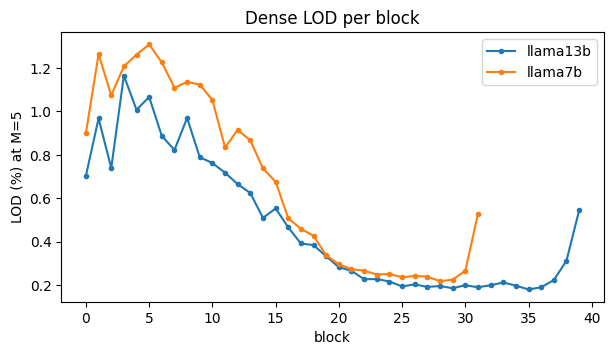

In [20]:
PAPER_T1 = {  # LLaMA-13B, M=7: LOD (%) and ppl
    ("dense", 0.0): (5.432, 5.090),
    ("wanda", 0.7): (5.716, 55.900), ("sparsegpt", 0.7): (6.645, 19.235), ("magnitude", 0.7): (5.322, 84539.445),
    ("wanda", 0.6): (5.433, 8.761), ("sparsegpt", 0.6): (6.044, 8.458), ("magnitude", 0.6): (5.322, 229.451),
}
r4 = load("r4")
rows = []
for _, r in r4.iterrows():
    for M in [5, 7]:
        dense_lod = lod_of(r.raw, M, "lod_dense")
        after = dense_lod if r.method == "dense" else lod_of(r.raw, M, "lod_pruned")
        if after is None:
            continue
        p = PAPER_T1.get((r.method, r.s)) if (r.model == "llama13b" and M == 7) else None
        # owlrepro stores LOD in percent already (alloc.block_outlier_ratio), so no * 100 here
        rows.append(dict(model=r.model, s=r.s, method=r.method, M=M,
                         lod_mean_pct=np.mean(after), lod_sum_pct=np.sum(after),
                         d_lod_mean_pct=np.mean(after) - np.mean(dense_lod),
                         d_lod_sum_pct=np.sum(after) - np.sum(dense_lod),
                         wiki=r.wiki, paper_lod_pct=p[0] if p else None,
                         paper_d_lod_pct=p[0] - PAPER_T1[("dense", 0.0)][0] if p else None,
                         paper_ppl=p[1] if p else None))
if rows:
    display(pd.DataFrame(rows).sort_values(["model", "M", "s", "method"]).round(3))
    print("Table 1 calls its LOD 'the summation across all layers', so both the mean and the sum over blocks are shown.")
    print("Its delta LOD column is a difference of sums: compare paper_d_lod_pct with d_lod_sum_pct.")

    # Figure 1: dense LOD per block (M=5)
    fig, ax = plt.subplots(figsize=(7, 3.5))
    for _, r in r4[r4.method == "dense"].iterrows():
        lod = lod_of(r.raw, 5)
        ax.plot(lod, "o-", ms=3, label=r.model)
    ax.set_xlabel("block"); ax.set_ylabel("LOD (%) at M=5"); ax.set_title("Dense LOD per block"); ax.legend()
    plt.show()

## 5. E2 runs: dense LOD of all ten models

One forward pass over the calibration data per model, for M in 3, 5, 7, 10. No evaluation, so these are quick, but they download every model (about 105 GB).

In [21]:
run_group("e2")

e2: 10 done, 0 to run, 0 skipped (need more than 39 GB)
e2: finished, 0 ok, 0 failed


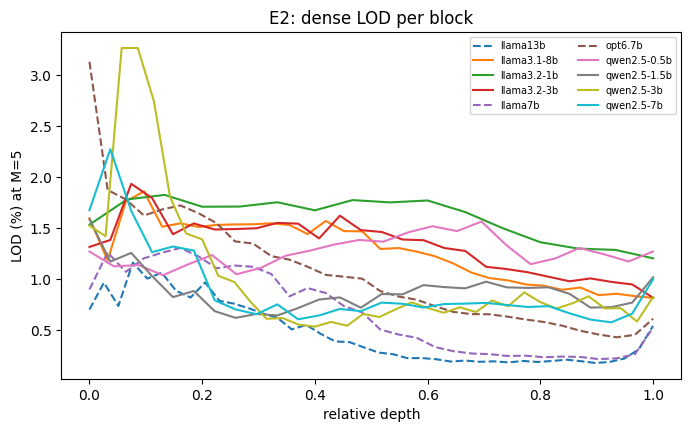

,model,family,params,cv_M3,cv_M5,cv_M7,cv_M10,U_M3,U_M5,U_M7,U_M10
4,llama7b,llama1,6.7,0.1713,0.5819,0.7822,0.9376,-0.0335,0.0789,0.0959,0.0589
0,llama13b,llama1,13.0,0.1524,0.6293,0.8386,0.9410,0.2074,0.1824,0.1014,0.0469
2,llama3.2-1b,llama3,1.2,0.0536,0.1248,0.1803,0.2533,-0.4226,-0.1780,-0.0097,0.0408
3,llama3.2-3b,llama3,3.2,0.0610,0.1990,0.2809,0.4082,-0.2046,-0.1222,0.0180,0.0607
1,llama3.1-8b,llama3,8.0,0.0592,0.2341,0.3584,0.4811,-0.2888,-0.0983,0.0337,0.0699
5,opt6.7b,opt,6.7,0.1238,0.5364,0.9775,0.8017,-0.2686,0.2550,0.1481,0.0299
6,qwen2.5-0.5b,qwen2.5,0.5,0.0748,0.1105,0.1711,0.1683,-0.2097,-0.1295,-0.0533,-0.0295
7,qwen2.5-1.5b,qwen2.5,1.5,0.1335,0.2265,0.2593,0.2441,-0.0583,0.1706,0.0962,0.0484
8,qwen2.5-3b,qwen2.5,3.1,0.2757,0.6748,0.7614,0.7205,0.3506,0.7305,0.3629,0.1486
9,qwen2.5-7b,qwen2.5,7.6,0.2078,0.4387,0.5212,0.5805,0.2602,0.4213,0.2405,0.1276


In [22]:
e2 = load("e2")
rows = []
fig, ax = plt.subplots(figsize=(8, 4.5))
for _, r in e2.iterrows():
    summ = r.raw.get("lod_dense_summary", {})
    rows.append(dict(model=r.model, family=r.family, params=r.params,
                     **{f"cv_M{M}": summ.get(str(float(M)), {}).get("cv") for M in [3, 5, 7, 10]},
                     **{f"U_M{M}": summ.get(str(float(M)), {}).get("u") for M in [3, 5, 7, 10]}))
    lod = np.array(lod_of(r.raw, 5))
    ax.plot(np.linspace(0, 1, len(lod)), lod, label=r.model,
            ls="-" if r.family in ("qwen2.5", "llama3") else "--")
ax.set_xlabel("relative depth"); ax.set_ylabel("LOD (%) at M=5"); ax.set_title("E2: dense LOD per block")
ax.legend(fontsize=7, ncol=2); plt.show()
E2_TABLE = pd.DataFrame(rows).sort_values(["family", "params"]) if rows else pd.DataFrame()
display(E2_TABLE.round(4))

## 6. E1: OWL vs uniform on Qwen2.5 and Llama-3.x

120 jobs: dense + Wanda/SparseGPT x uniform/OWL x 50/60/70% for seven models (zero-shot at 70%), three shuffled-OWL controls per model, and two extra calibration seeds for the two smallest models. Small models first, because they are fast and fit any card.

In [23]:
run_group("e1", models=["qwen2.5-0.5b", "llama3.2-1b", "qwen2.5-1.5b", "qwen2.5-3b", "llama3.2-3b"])

e1: 26 done, 62 to run, 0 skipped (need more than 39 GB)
  estimated time: about 2.0 h on NVIDIA A100-SXM4-40GB (rescaled from 100 finished jobs), plus about 5 min of downloads for models that are not cached yet
[1/62] 02:46 results/e1/qwen2.5-0.5b_dense.json (about 2 min)
    results/e1/qwen2.5-0.5b_dense.json has no zero-shot results yet, running the job again
    
    [transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (299078 > 131072). Running this sequence through the model will result in indexing errors
    wikitext2 ppl 13.077 (10s)
    `pretrained` model kwarg is not of type `str`. Many other model arguments may be ignored. Please do not launch via accelerate or use `parallelize=True` if passing an existing model this way.
    Passed an already-initialized model through `pretrained`, assuming single-process call to evaluate() or custom distributed integration
    [Task: boolq] metric acc is defined, but aggregation i

In [24]:
run_group("e1")  # Qwen2.5-7B and Llama-3.1-8B (about 18-21 GB)

e1: 96 done, 24 to run, 0 skipped (need more than 39 GB)
  estimated time: about 2.6 h on NVIDIA A100-SXM4-40GB (rescaled from 162 finished jobs), plus about 9 min of downloads for models that are not cached yet
[1/24] 07:06 results/e1/qwen2.5-7b_dense.json (about 9 min)
    results/e1/qwen2.5-7b_dense.json has no zero-shot results yet, running the job again
    
    
    [transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (299078 > 131072). Running this sequence through the model will result in indexing errors
    wikitext2 ppl 6.851 (28s)
    `pretrained` model kwarg is not of type `str`. Many other model arguments may be ignored. Please do not launch via accelerate or use `parallelize=True` if passing an existing model this way.
    Passed an already-initialized model through `pretrained`, assuming single-process call to evaluate() or custom distributed integration
    [Task: boolq] metric acc is defined, but aggregation i

OWL gain in log perplexity, $\Delta L = \log \mathrm{PPL}_{\mathrm{uni}} - \log \mathrm{PPL}_{\mathrm{OWL}}$ (positive = OWL helps), per method. LLaMA-1/OPT points at 70% come from R1. `loss_vs_dense` is $\log(\mathrm{PPL}/\mathrm{PPL}_{\mathrm{dense}})$ of the OWL model. `sparsity_uni` and `sparsity_owl` are the measured global sparsities.

,model,params,method,s,ppl_uni,ppl_owl,drop,dL,loss_vs_dense,zs_uni,zs_owl,sparsity_uni,sparsity_owl
8,llama3.2-1b,1.2,sparsegpt,0.5,19.046,18.751,0.296,0.016,0.653,NaN,NaN,0.5,0.5
14,llama3.2-3b,3.2,sparsegpt,0.5,12.282,12.135,0.147,0.012,0.440,NaN,NaN,0.5,0.5
2,llama3.1-8b,8.0,sparsegpt,0.5,9.294,9.477,-0.183,-0.020,0.418,NaN,NaN,0.5,0.5
24,qwen2.5-0.5b,0.5,sparsegpt,0.5,20.303,21.224,-0.921,-0.044,0.484,NaN,NaN,0.5,0.5
30,qwen2.5-1.5b,1.5,sparsegpt,0.5,13.055,12.930,0.125,0.010,0.333,NaN,NaN,0.5,0.5
36,qwen2.5-3b,3.1,sparsegpt,0.5,10.747,11.072,-0.325,-0.030,0.321,NaN,NaN,0.5,0.5
42,qwen2.5-7b,7.6,sparsegpt,0.5,8.428,8.540,-0.112,-0.013,0.220,NaN,NaN,0.5,0.5
9,llama3.2-1b,1.2,sparsegpt,0.6,49.243,43.069,6.173,0.134,1.485,NaN,NaN,0.6,0.6
15,llama3.2-3b,3.2,sparsegpt,0.6,22.174,21.068,1.106,0.051,0.991,NaN,NaN,0.6,0.6
3,llama3.1-8b,8.0,sparsegpt,0.6,15.288,14.384,0.904,0.061,0.835,NaN,NaN,0.6,0.6


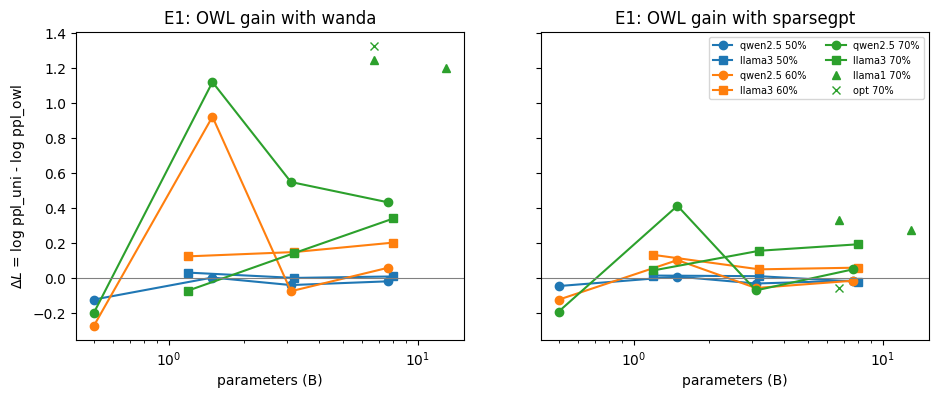

In [25]:
allr = load("r1", "e1")
main = allr[(allr.seed == 0) & (allr.perm == 0)]
dense_ppl = main[main.method == "dense"].set_index("model").wiki


def gains(df):
    rows = []
    for (m, meth, s), g in df[df.method.isin(["wanda", "sparsegpt"])].groupby(["model", "method", "s"]):
        g = g.set_index("alloc")
        if not {"uniform", "owl"} <= set(g.index):
            continue
        u, o = g.loc["uniform"], g.loc["owl"]
        rows.append(dict(model=m, family=FAMILY.get(m), params=u.params, method=meth, s=s,
                         ppl_uni=u.wiki, ppl_owl=o.wiki, drop=u.wiki - o.wiki,
                         dL=math.log(u.wiki) - math.log(o.wiki),
                         loss_vs_dense=math.log(o.wiki / dense_ppl[m]) if m in dense_ppl else np.nan,
                         zs_uni=u.zs, zs_owl=o.zs, sparsity_uni=u.sparsity, sparsity_owl=o.sparsity))
    return pd.DataFrame(rows)


G = gains(main)
if len(G):
    display(G.sort_values(["method", "s", "family", "params"]).drop(columns=["family"]).round(3))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
    for ax, meth in zip(axes, ["wanda", "sparsegpt"]):
        for i, s in enumerate([0.5, 0.6, 0.7]):
            for fam, mk in [("qwen2.5", "o-"), ("llama3", "s-"), ("llama1", "^"), ("opt", "x")]:
                g = G[(G.method == meth) & (G.s == s) & (G.family == fam)].sort_values("params")
                if len(g):
                    ax.plot(g.params, g.dL, mk, color=f"C{i}", label=f"{fam} {int(s * 100)}%")
        ax.axhline(0, color="gray", lw=0.8); ax.set_xscale("log"); ax.set_xlabel("parameters (B)")
        ax.set_title(f"E1: OWL gain with {meth}")
    axes[0].set_ylabel(r"$\Delta L$ = log ppl_uni - log ppl_owl"); axes[1].legend(fontsize=7, ncol=2); plt.show()

**Shuffle control** (Wanda, 70%): OWL's block sparsities in a random order. If the shuffled runs are about as good as OWL, the gain comes from the spread of sparsities, not from matching them to the LOD. **Calibration seeds**: the spread of $\Delta L$ over three C4 samples for the two smallest models.

In [26]:
e1 = load("e1")
w70 = e1[(e1.method == "wanda") & (e1.s == 0.7) & (e1.seed == 0)]
rows = []
for m, g in w70.groupby("model"):
    uni = g[g.alloc == "uniform"].wiki
    owl = g[(g.alloc == "owl") & (g.perm == 0)].wiki
    shuf = g[g.alloc == "owl_shuffle"].wiki
    if len(uni) and len(owl):
        u = uni.iloc[0]
        rows.append(dict(model=m, params=g.params.iloc[0], ppl_uni=u, ppl_owl=owl.iloc[0],
                         ppl_shuffle=list(shuf.round(2)), dL_owl=math.log(u / owl.iloc[0]),
                         dL_shuffle_mean=np.mean([math.log(u / x) for x in shuf]) if len(shuf) else np.nan))
if rows:
    print("Shuffle control, Wanda 70%"); display(pd.DataFrame(rows).sort_values("params").round(3))

seeds = e1[(e1.method == "wanda") & (e1.s == 0.7) & (e1.perm == 0) & e1.alloc.isin(["uniform", "owl"])]
rows = []
for (m, sd), g in seeds.groupby(["model", "seed"]):
    g = g.set_index("alloc")
    if {"uniform", "owl"} <= set(g.index):
        rows.append(dict(model=m, seed=sd, ppl_uni=g.wiki["uniform"], ppl_owl=g.wiki["owl"],
                         dL=math.log(g.wiki["uniform"] / g.wiki["owl"])))
if rows:
    sd = pd.DataFrame(rows)
    sd = sd[sd.model.isin(sd[sd.seed > 0].model)]
    if len(sd):
        print("Calibration seeds, Wanda 70%"); display(sd.round(3))
        display(sd.groupby("model").dL.agg(["mean", "std"]).round(3))

Shuffle control, Wanda 70%


,model,params,ppl_uni,ppl_owl,ppl_shuffle,dL_owl,dL_shuffle_mean
3,qwen2.5-0.5b,0.5,462.193,564.028,"[623.35, 494.59, 318.56]",-0.199,0.002
1,llama3.2-1b,1.2,435.213,466.724,"[538.71, 538.97, 963.04]",-0.070,-0.407
4,qwen2.5-1.5b,1.5,766.484,249.807,"[1088.62, 1344.88, 769.1]",1.121,-0.306
5,qwen2.5-3b,3.1,155.678,89.810,"[135.86, 149.01, 204.25]",0.550,-0.031
2,llama3.2-3b,3.2,145.003,125.519,"[149.07, 200.66, 173.17]",0.144,-0.177
6,qwen2.5-7b,7.6,75.426,48.856,"[67.05, 101.63, 107.79]",0.434,-0.179
0,llama3.1-8b,8.0,111.952,79.539,"[125.9, 123.26, 144.66]",0.342,-0.157


Calibration seeds, Wanda 70%


,model,seed,ppl_uni,ppl_owl,dL
1,llama3.2-1b,0,435.213,466.724,-0.070
2,llama3.2-1b,1,370.588,330.389,0.115
3,llama3.2-1b,2,423.924,396.644,0.067
5,qwen2.5-0.5b,0,462.193,564.028,-0.199
6,qwen2.5-0.5b,1,392.146,395.676,-0.009
7,qwen2.5-0.5b,2,420.969,404.771,0.039


,mean,std
model,,
llama3.2-1b,0.037,0.096
qwen2.5-0.5b,-0.056,0.126


## 7. E2: does the LOD predict the OWL gain?

Spearman correlation across models between dense-LOD unevenness (CV, and the U-shape contrast U) at M = 5 and $\Delta L$ at 70%, per method. With ten related models this is exploratory, so we also show a bootstrap 95% interval and the result with each family left out.

wanda     cv_M5  n=10 rho=+0.77 95% CI [+0.12, +0.99] leave-one-family-out {'llama1': 0.81, 'llama3': 0.43, 'opt': 0.8, 'qwen2.5': 0.77}
wanda     U_M5   n=10 rho=+0.66 95% CI [-0.09, +0.99] leave-one-family-out {'llama1': 0.79, 'llama3': 0.04, 'opt': 0.68, 'qwen2.5': 0.94}


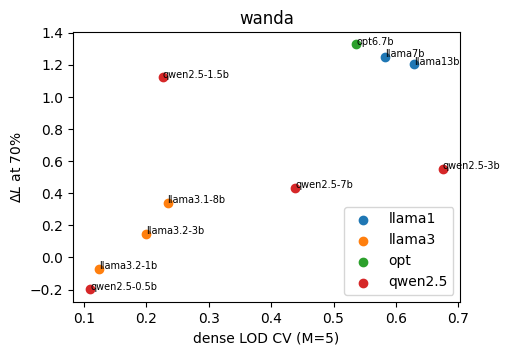

sparsegpt cv_M5  n=10 rho=+0.18 95% CI [-0.70, +0.84] leave-one-family-out {'llama1': -0.02, 'llama3': 0.04, 'opt': 0.28, 'qwen2.5': 0.6}
sparsegpt U_M5   n=10 rho=-0.01 95% CI [-0.77, +0.79] leave-one-family-out {'llama1': -0.02, 'llama3': -0.18, 'opt': 0.2, 'qwen2.5': 0.09}


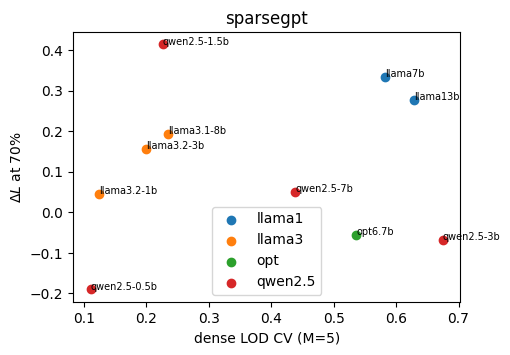

In [27]:
from scipy.stats import spearmanr

if len(E2_TABLE) and len(G):
    rng = np.random.default_rng(0)
    for meth in ["wanda", "sparsegpt"]:
        d = G[(G.method == meth) & (G.s == 0.7)].merge(E2_TABLE[["model", "cv_M5", "U_M5"]], on="model")
        if len(d) < 4:
            print(meth, ": need at least 4 models with both E2 and 70% results, have", len(d)); continue
        for x in ["cv_M5", "U_M5"]:
            rho = spearmanr(d[x], d.dL)[0]
            boot = []
            for _ in range(2000):
                b = d.sample(len(d), replace=True, random_state=rng.integers(1 << 31))
                if b[x].nunique() > 1 and b.dL.nunique() > 1:
                    boot.append(spearmanr(b[x], b.dL)[0])
            lo, hi = np.nanpercentile(boot, [2.5, 97.5])
            lofo = {f: round(float(spearmanr(g[x], g.dL)[0]), 2)
                    for f in d.family.unique() if len(g := d[d.family != f]) >= 3}
            print(f"{meth:9} {x:6} n={len(d)} rho={rho:+.2f} 95% CI [{lo:+.2f}, {hi:+.2f}] leave-one-family-out {lofo}")
        fig, ax = plt.subplots(figsize=(5, 3.5))
        for fam, g in d.groupby("family"):
            ax.scatter(g.cv_M5, g.dL, label=fam)
            for _, r in g.iterrows():
                ax.annotate(r.model, (r.cv_M5, r.dL), fontsize=7)
        ax.set_xlabel("dense LOD CV (M=5)"); ax.set_ylabel(r"$\Delta L$ at 70%"); ax.set_title(meth); ax.legend()
        plt.show()

## 8. E3: M and lambda grid, then transfer

Grid on Qwen2.5-1.5B and Llama-3.2-1B (Wanda, 70%). The setting is picked by **C4 validation perplexity**, which is held out from the C4 training shard used for calibration. WikiText-2 is only reported. The choice for each tuning model is then applied to its whole family.

In [28]:
run_group("e3")

e3: 0 done, 40 to run, 0 skipped (need more than 39 GB)
  estimated time: about 0.7 h on NVIDIA A100-SXM4-40GB (rescaled from 186 finished jobs), plus about 2 min of downloads for models that are not cached yet
[1/40] 10:34 results/e3/qwen2.5-1.5b_wanda_owl_s70_M3_l0.02.json (about 1 min)
    
    [transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (528225 > 131072). Running this sequence through the model will result in indexing errors
    c4 ppl 762.268 (17s)
    wikitext2 ppl 1064.040 (12s)
    sparsity 0.6998, wrote results/e3/qwen2.5-1.5b_wanda_owl_s70_M3_l0.02.json
  done in 1.3 min -> results/e3/qwen2.5-1.5b_wanda_owl_s70_M3_l0.02.json
[2/40] 10:36 results/e3/qwen2.5-1.5b_wanda_owl_s70_M3_l0.05.json (about 1 min)
    
    [transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (528225 > 131072). Running this sequence through the model will result in indexing erro

qwen2.5-1.5b: best on C4 val M=7, lambda=0.2 (C4 137.95, WikiText-2 97.67)


lam,0.02,0.05,0.08,0.10,0.20
M,,,,,
3.0,762.27,625.61,534.10,418.35,230.64
5.0,616.64,452.51,239.27,168.08,146.08
7.0,479.14,424.79,252.90,157.62,137.95
10.0,643.44,418.46,216.26,156.89,141.06


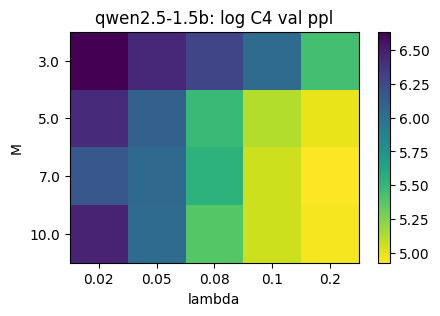

llama3.2-1b: best on C4 val M=10, lambda=0.05 (C4 328.76, WikiText-2 286.34)


lam,0.02,0.05,0.08,0.10,0.20
M,,,,,
3.0,502.35,440.69,462.85,458.53,900.97
5.0,450.29,445.80,492.17,479.42,1366.61
7.0,424.67,362.36,383.05,396.08,849.91
10.0,382.25,328.76,346.75,337.37,472.44


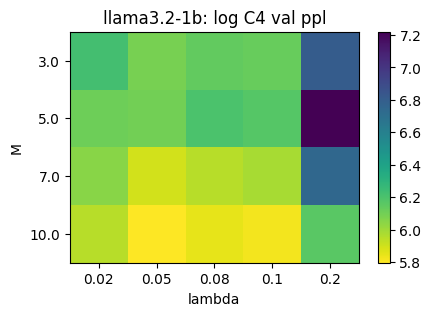

tuned: {'qwen2.5': (np.float64(7.0), np.float64(0.2)), 'llama3': (np.float64(10.0), np.float64(0.05))}


In [29]:
e3 = load("e3")
TUNED = {}
TUNE_MODELS = {"qwen2.5": "qwen2.5-1.5b", "llama3": "llama3.2-1b"}
for fam, m in TUNE_MODELS.items():
    g = e3[(e3.model == m) & e3.c4.notna()]
    if not len(g):
        continue
    grid = g.pivot_table(index="M", columns="lam", values="c4")
    best = g.loc[g.c4.idxmin()]
    TUNED[fam] = (best.M, best.lam)
    print(f"{m}: best on C4 val M={best.M:g}, lambda={best.lam:g} (C4 {best.c4:.2f}, WikiText-2 {best.wiki:.2f})")
    display(grid.round(2))
    fig, ax = plt.subplots(figsize=(5, 3))
    im = ax.imshow(np.log(grid.values), cmap="viridis_r")
    ax.set_xticks(range(len(grid.columns)), grid.columns); ax.set_yticks(range(len(grid.index)), grid.index)
    ax.set_xlabel("lambda"); ax.set_ylabel("M"); ax.set_title(f"{m}: log C4 val ppl"); fig.colorbar(im)
    plt.show()
print("tuned:", TUNED)

Transfer: run tuned OWL (Wanda, 70%) on every model of each family. Jobs that already exist, such as the tuning models themselves or a choice equal to the default, are skipped.

In [30]:
transfer = []
for short in make_jobs.NEW_MODELS:
    fam = FAMILY[short]
    if fam in TUNED:
        M, lam = TUNED[fam]
        transfer.append(make_jobs.job("e3", short, "wanda", "owl", 0.7, M=M, lam=lam, evals="c4,wikitext2"))
run_lines(transfer, label="e3 transfer")

e3 transfer: 2 done, 5 to run, 0 skipped (need more than 39 GB)
  estimated time: about 0.2 h on NVIDIA A100-SXM4-40GB (rescaled from 226 finished jobs), plus about 13 min of downloads for models that are not cached yet
[1/5] 11:19 results/e3/qwen2.5-0.5b_wanda_owl_s70_M7_l0.2.json (about 1 min)
    
    [transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (528225 > 131072). Running this sequence through the model will result in indexing errors
    c4 ppl 7771.375 (13s)
    wikitext2 ppl 8092.828 (9s)
    sparsity 0.6996, wrote results/e3/qwen2.5-0.5b_wanda_owl_s70_M7_l0.2.json
  done in 1.1 min -> results/e3/qwen2.5-0.5b_wanda_owl_s70_M7_l0.2.json
[2/5] 11:20 results/e3/qwen2.5-3b_wanda_owl_s70_M7_l0.2.json (about 2 min)
    
    [transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (528225 > 131072). Running this sequence through the model will result in indexing err

In [31]:
e3 = load("e3")
rows = []
for short in make_jobs.NEW_MODELS:
    fam = FAMILY[short]
    if fam not in TUNED:
        continue
    M, lam = TUNED[fam]
    t = e3[(e3.model == short) & (e3.M == M) & (e3.lam == lam)]
    b = G[(G.model == short) & (G.method == "wanda") & (G.s == 0.7)]
    if len(t) and len(b):
        b = b.iloc[0]
        rows.append(dict(model=short, M=M, lam=lam, ppl_uni=b.ppl_uni, ppl_owl_default=b.ppl_owl,
                         ppl_owl_tuned=t.wiki.iloc[0], dL_default=b.dL,
                         dL_tuned=math.log(b.ppl_uni / t.wiki.iloc[0])))
if rows:
    display(pd.DataFrame(rows).round(3))

,model,M,lam,ppl_uni,ppl_owl_default,ppl_owl_tuned,dL_default,dL_tuned
0,qwen2.5-0.5b,7.0,0.20,462.193,564.028,8092.828,-0.199,-2.863
1,qwen2.5-1.5b,7.0,0.20,766.484,249.807,97.671,1.121,2.060
2,qwen2.5-3b,7.0,0.20,155.678,89.810,94.241,0.550,0.502
3,qwen2.5-7b,7.0,0.20,75.426,48.856,50.391,0.434,0.403
4,llama3.2-1b,10.0,0.05,435.213,466.724,286.339,-0.070,0.419
5,llama3.2-3b,10.0,0.05,145.003,125.519,120.996,0.144,0.181
6,llama3.1-8b,10.0,0.05,111.952,79.539,90.742,0.342,0.210


## 9. R3 with the authors' zero-shot scripts (optional)

This reproduces Table 4 exactly with the authors' pipeline (lm-eval 0.3.0 from H2O). It needs:
1. The six pruned LLaMA-7B checkpoints saved to `ckpt/` (about 13 GB each, about 80 GB in total). The next cell does this when `RUN_R3_SAVE = True`.
2. A **separate** conda env, because lm-eval 0.3.0 conflicts with this one:
   ```
   conda create -n owl-lmeval03 python=3.9 -y
   conda activate owl-lmeval03
   pip install torch transformers lm-eval==0.3.0
   git clone https://github.com/luuyin/OWL.git
   cd OWL/zero_shot_benchmark
   ```
3. Their scripts are bash (`scripts/data_genration/run.sh`, `scripts/benchmark/run.sh`, `scripts/benchmark/eval.sh`). On Windows, run them in Git Bash or WSL. Set `model=` in `scripts/benchmark/run.sh` to each checkpoint folder in turn.

We have not run these scripts here, so check their README first.

In [32]:
RUN_R3_SAVE = False  # set True when you have ~80 GB free

r3 = []
for method, alloc in [("dense", "uniform"), ("magnitude", "uniform"), ("wanda", "uniform"), ("wanda", "owl"),
                      ("sparsegpt", "uniform"), ("sparsegpt", "owl")]:
    line = make_jobs.job("r3", "llama7b", method, alloc, 0.7, evals="none")
    stem = Path(job_args(line)[1]["--out"]).stem
    r3.append(f"{line} --save_model ckpt/{stem}")
if RUN_R3_SAVE:
    run_lines(r3, label="r3 checkpoints")
else:
    run_lines(r3, label="r3 checkpoints", dry_run=True)

r3 checkpoints: 0 done, 6 to run, 0 skipped (need more than 39 GB)
  estimated time: about 0.3 h on NVIDIA A100-SXM4-40GB (rescaled from 231 finished jobs), plus about 4 min of downloads for models that are not cached yet
  would run (  1 min): results/r3/llama7b_dense.json
  would run (  1 min): results/r3/llama7b_magnitude_uniform_s70.json
  would run (  2 min): results/r3/llama7b_wanda_uniform_s70.json
  would run (  3 min): results/r3/llama7b_wanda_owl_s70_M5_l0.08.json
  would run (  4 min): results/r3/llama7b_sparsegpt_uniform_s70.json
  would run (  5 min): results/r3/llama7b_sparsegpt_owl_s70_M5_l0.08.json


## 10. Collect everything into `results/summary.csv`

In [33]:
subprocess.run([sys.executable, "scripts/collect.py"], cwd=ROOT)
status()
pd.read_csv(ROOT / "results" / "summary.csv")

talk: 84/84 done
r1: 18/18 done
r2: 30/30 done
r4: 14/14 done
e1: 120/120 done
e2: 10/10 done
e3: 40/40 done


,group,job,model,method,alloc,sparsity_target,sparsity,M,lam,seed,calib,nsamples,seqlen,dtype,ppl_wikitext2,ppl_c4,ppl_viwiki,zs_mean_acc,lod_M,lod_sum,lod_mean,lod_cv,lod_u,load_seconds,alloc_seconds,prune_seconds,minutes,max_gpu_mem_gb,gpu,torch,transformers,started
0,e1,llama3.1-8b_dense,meta-llama/Llama-3.1-8B,dense,NaN,0.0,0.0000,5.0,0.08,0,c4,128,2048,torch.bfloat16,6.239644,NaN,NaN,0.653224,NaN,NaN,NaN,NaN,NaN,86.5,NaN,NaN,11.2,19.41,NVIDIA A100-SXM4-40GB,2.14.1+cu130,5.22.1,2026-11-12 08:17:55
1,e1,llama3.1-8b_sparsegpt_owl_s50_M5_l0.08,meta-llama/Llama-3.1-8B,sparsegpt,owl,0.5,0.5000,5.0,0.08,0,c4,128,2048,torch.bfloat16,9.477063,NaN,NaN,NaN,5.0,41.047,1.2827,0.2340,-0.0983,9.0,24.7,591.1,11.1,22.25,NVIDIA A100-SXM4-40GB,2.14.1+cu130,5.22.1,2026-11-12 08:43:50
2,e1,llama3.1-8b_sparsegpt_owl_s60_M5_l0.08,meta-llama/Llama-3.1-8B,sparsegpt,owl,0.6,0.6000,5.0,0.08,0,c4,128,2048,torch.bfloat16,14.384168,NaN,NaN,NaN,5.0,41.047,1.2827,0.2340,-0.0983,9.6,24.7,582.9,11.0,22.25,NVIDIA A100-SXM4-40GB,2.14.1+cu130,5.22.1,2026-11-12 09:09:23
3,e1,llama3.1-8b_sparsegpt_owl_s70_M5_l0.08,meta-llama/Llama-3.1-8B,sparsegpt,owl,0.7,0.7000,5.0,0.08,0,c4,128,2048,torch.bfloat16,32.861637,NaN,NaN,0.460766,5.0,41.047,1.2827,0.2340,-0.0983,9.1,24.6,578.1,20.0,22.25,NVIDIA A100-SXM4-40GB,2.14.1+cu130,5.22.1,2026-11-12 10:02:28
4,e1,llama3.1-8b_sparsegpt_uniform_s50,meta-llama/Llama-3.1-8B,sparsegpt,uniform,0.5,0.5000,5.0,0.08,0,c4,128,2048,torch.bfloat16,9.293974,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.0,0.0,582.2,10.5,22.25,NVIDIA A100-SXM4-40GB,2.14.1+cu130,5.22.1,2026-11-12 08:33:12
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
233,r4,llama7b_sparsegpt_uniform_s60_lod,huggyllama/llama-7b,sparsegpt,uniform,0.6,0.6000,5.0,0.08,0,c4,128,2048,torch.float16,10.444339,NaN,NaN,NaN,5.0,21.731,0.6791,0.5819,0.0789,6.9,0.0,467.8,9.3,18.53,NVIDIA A100-SXM4-40GB,2.14.1+cu130,5.22.1,2026-11-11 18:38:48
234,r4,llama7b_sparsegpt_uniform_s70_lod,huggyllama/llama-7b,sparsegpt,uniform,0.7,0.7000,5.0,0.08,0,c4,128,2048,torch.float16,26.396591,NaN,NaN,NaN,5.0,21.731,0.6791,0.5819,0.0789,6.8,0.0,474.6,9.4,18.53,NVIDIA A100-SXM4-40GB,2.14.1+cu130,5.22.1,2026-11-11 18:53:20
235,r4,llama7b_wanda_uniform_s60_lod,huggyllama/llama-7b,wanda,uniform,0.6,0.5999,5.0,0.08,0,c4,128,2048,torch.float16,10.696953,NaN,NaN,NaN,5.0,21.731,0.6791,0.5819,0.0789,6.8,0.0,44.2,2.2,18.11,NVIDIA A100-SXM4-40GB,2.14.1+cu130,5.22.1,2026-11-11 18:36:28
236,r4,llama7b_wanda_uniform_s70_lod,huggyllama/llama-7b,wanda,uniform,0.7,0.6999,5.0,0.08,0,c4,128,2048,torch.float16,84.837379,NaN,NaN,NaN,5.0,21.731,0.6791,0.5819,0.0789,7.1,0.0,44.1,2.2,18.11,NVIDIA A100-SXM4-40GB,2.14.1+cu130,5.22.1,2026-11-11 18:50:59
